In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

df = pd.read_csv("phishing.csv")
print("Ukuran data:", df.shape)
display(df.head())

Ukuran data: (11054, 32)


,Index,UsingIP,LongURL,ShortURL,Symbol@,Redirecting//,PrefixSuffix-,SubDomains,HTTPS,DomainRegLen,Favicon,NonStdPort,HTTPSDomainURL,RequestURL,AnchorURL,LinksInScriptTags,ServerFormHandler,InfoEmail,AbnormalURL,WebsiteForwarding,StatusBarCust,DisableRightClick,UsingPopupWindow,IframeRedirection,AgeofDomain,DNSRecording,WebsiteTraffic,PageRank,GoogleIndex,LinksPointingToPage,StatsReport,class
0,0,1,1,1,1,1,-1,0,1,-1,1,1,-1,1,0,-1,-1,1,1,0,1,1,1,1,-1,-1,0,-1,1,1,1,-1
1,1,1,0,1,1,1,-1,-1,-1,-1,1,1,-1,1,0,-1,-1,-1,-1,0,1,1,1,1,1,-1,1,-1,1,0,-1,-1
2,2,1,0,1,1,1,-1,-1,-1,1,1,1,-1,-1,0,0,-1,1,1,0,1,1,1,1,-1,-1,1,-1,1,-1,1,-1
3,3,1,0,-1,1,1,-1,1,1,-1,1,1,1,1,0,0,-1,1,1,0,-1,1,-1,1,-1,-1,0,-1,1,1,1,1
4,4,-1,0,-1,1,-1,-1,1,1,-1,1,1,-1,1,0,0,-1,-1,-1,0,1,1,1,1,1,1,1,-1,1,-1,-1,1


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11054 entries, 0 to 11053
Data columns (total 32 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Index                11054 non-null  int64
 1   UsingIP              11054 non-null  int64
 2   LongURL              11054 non-null  int64
 3   ShortURL             11054 non-null  int64
 4   Symbol@              11054 non-null  int64
 5   Redirecting//        11054 non-null  int64
 6   PrefixSuffix-        11054 non-null  int64
 7   SubDomains           11054 non-null  int64
 8   HTTPS                11054 non-null  int64
 9   DomainRegLen         11054 non-null  int64
 10  Favicon              11054 non-null  int64
 11  NonStdPort           11054 non-null  int64
 12  HTTPSDomainURL       11054 non-null  int64
 13  RequestURL           11054 non-null  int64
 14  AnchorURL            11054 non-null  int64
 15  LinksInScriptTags    11054 non-null  int64
 16  ServerFormHandler    11054 non-nu

Total missing value: 0
Duplikat baris (tanpa Index): 5205
Nilai unik pada fitur: [np.int64(-1), np.int64(0), np.int64(1)]

Distribusi kelas (1 = sah, -1 = phishing):
class
 1    6157
-1    4897
Name: count, dtype: int64
class
 1    0.557
-1    0.443
Name: proportion, dtype: float64


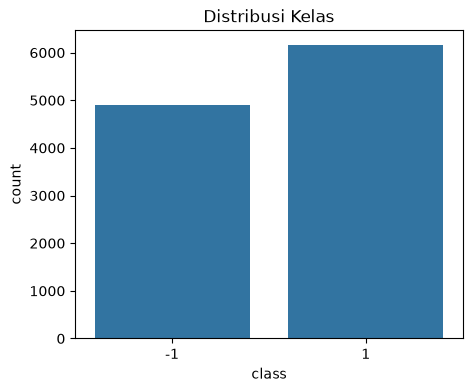

In [3]:
print("Total missing value:", df.isna().sum().sum())
print("Duplikat baris (tanpa Index):", df.drop(columns="Index").duplicated().sum())
print("Nilai unik pada fitur:", sorted(set(df.drop(columns=["Index", "class"]).values.ravel())))

print("\nDistribusi kelas (1 = sah, -1 = phishing):")
print(df["class"].value_counts())
print(df["class"].value_counts(normalize=True).round(4))

plt.figure(figsize=(5, 4))
sns.countplot(x="class", data=df)
plt.title("Distribusi Kelas")
plt.show()

In [4]:
TARGET = "class"

X = df.drop(columns=["Index", TARGET])
y = (df[TARGET] == 1).astype(int)     # 1 = sah, 0 = phishing

print("Fitur  :", X.shape)
print("Target :", y.value_counts().to_dict(), "(0 = phishing, 1 = sah)")

Fitur  : (11054, 30)
Target : {1: 6157, 0: 4897} (0 = phishing, 1 = sah)


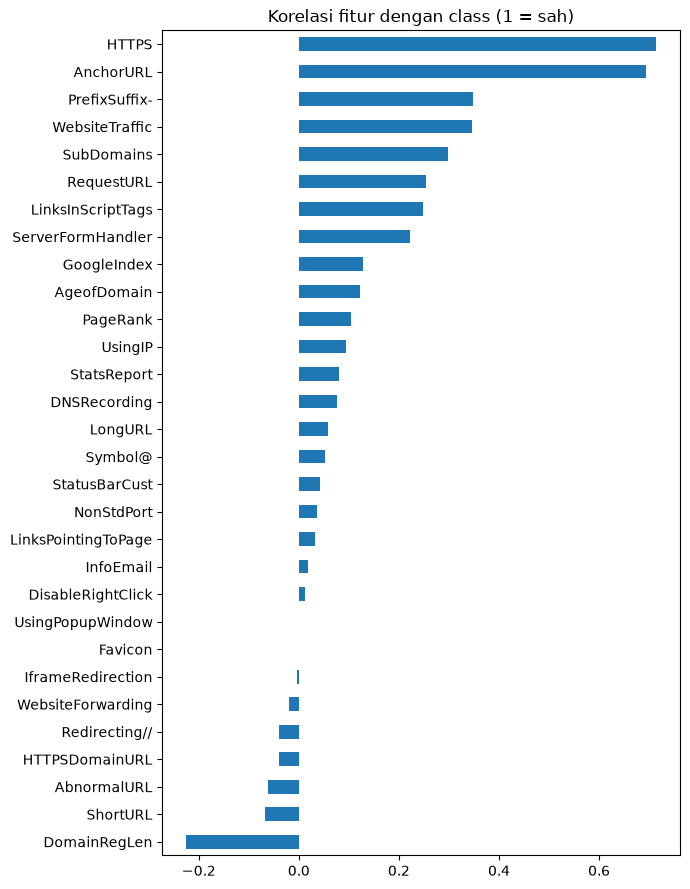

In [5]:
# Korelasi tiap fitur dengan target
corr = X.corrwith(y).sort_values()
plt.figure(figsize=(7, 9))
corr.plot(kind="barh")
plt.title("Korelasi fitur dengan class (1 = sah)")
plt.tight_layout()
plt.show()

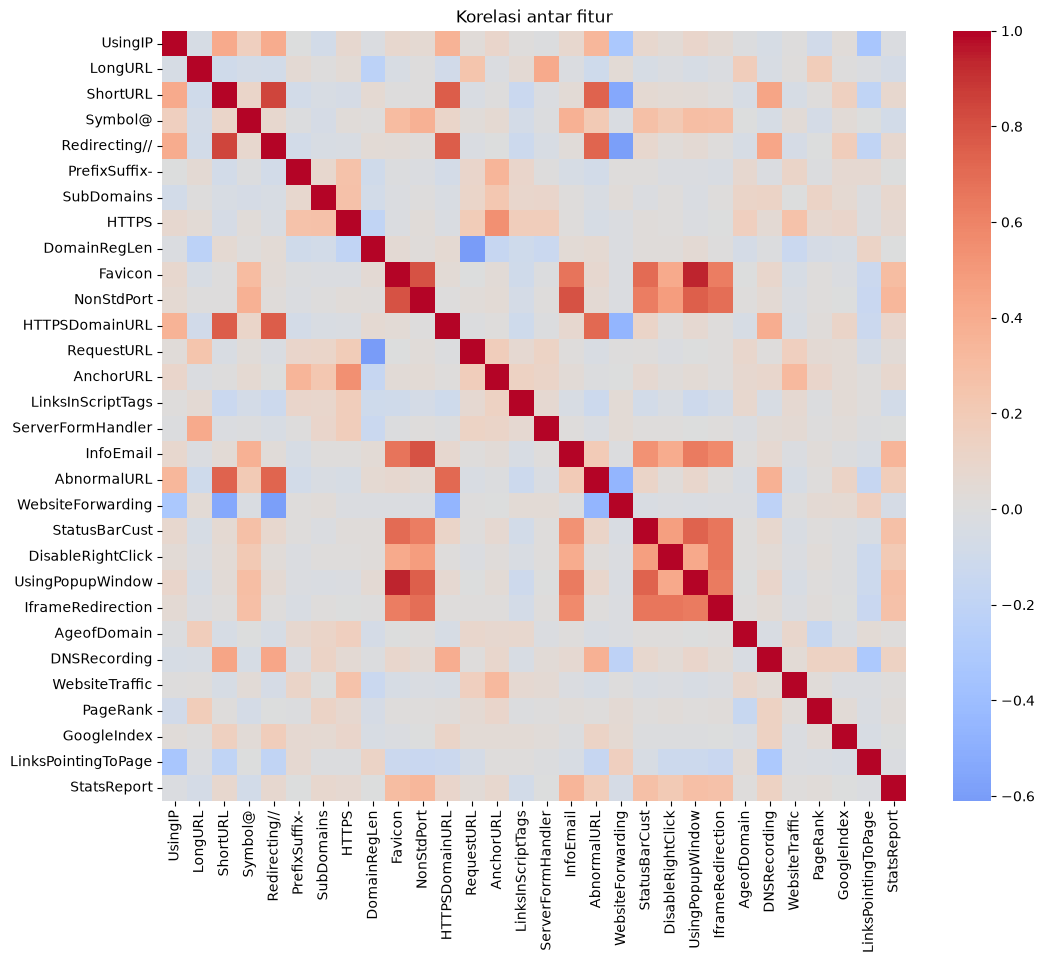

In [6]:
# Heatmap korelasi antar fitur
plt.figure(figsize=(12, 10))
sns.heatmap(X.corr(), cmap="coolwarm", center=0)
plt.title("Korelasi antar fitur")
plt.show()

In [7]:
# Proporsi kelas per nilai pada 4 fitur paling berkorelasi
for col in corr.abs().sort_values(ascending=False).index[:4]:
    display(pd.crosstab(X[col], y, normalize="index").round(3)
            .rename(columns={0: "phishing", 1: "sah"}).rename_axis(col))

class,phishing,sah
HTTPS,,
-1,0.858,0.142
0,0.982,0.018
1,0.111,0.889


class,phishing,sah
AnchorURL,,
-1,0.989,0.011
0,0.281,0.719
1,0.062,0.938


class,phishing,sah
PrefixSuffix-,,
-1,0.511,0.489
1,0.000,1.000


class,phishing,sah
WebsiteTraffic,,
-1,0.630,0.370
0,0.669,0.331
1,0.258,0.742


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (8843, 30) | Test: (2211, 30)


In [9]:
models = {
    "Logistic Regression": Pipeline([("sc", StandardScaler()),
                                     ("clf", LogisticRegression(max_iter=2000))]),
    "KNN": Pipeline([("sc", StandardScaler()),
                     ("clf", KNeighborsClassifier(n_neighbors=5))]),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

rows = []
for nama, model in models.items():
    hasil = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"Model": nama, **{m: hasil[f"test_{m}"].mean() for m in scoring}})

hasil_cv = pd.DataFrame(rows).set_index("Model").round(4).sort_values("f1", ascending=False)
display(hasil_cv)

,accuracy,precision,recall,f1,roc_auc
Model,,,,,
Random Forest,0.9709,0.9676,0.9807,0.9741,0.9951
Gradient Boosting,0.9648,0.9661,0.9710,0.9685,0.9958
Decision Tree,0.9453,0.9587,0.9425,0.9505,0.9835
KNN,0.9403,0.9428,0.9505,0.9466,0.9804
Logistic Regression,0.9236,0.9229,0.9415,0.9321,0.9777


In [10]:
fitted, rows = {}, []
for nama, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    fitted[nama] = model
    rows.append({
        "Model": nama,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

hasil_test = pd.DataFrame(rows).set_index("Model").round(4).sort_values("F1", ascending=False)
display(hasil_test)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Random Forest,0.9738,0.9688,0.9846,0.9767,0.9945
Gradient Boosting,0.9697,0.9686,0.9773,0.9729,0.9956
Decision Tree,0.9534,0.9654,0.9505,0.9579,0.9841
KNN,0.9408,0.9443,0.9497,0.9470,0.9844
Logistic Regression,0.9389,0.9406,0.9505,0.9455,0.9824


Model terbaik: Random Forest
              precision    recall  f1-score   support

Phishing (0)       0.98      0.96      0.97       979
     Sah (1)       0.97      0.98      0.98      1232

    accuracy                           0.97      2211
   macro avg       0.97      0.97      0.97      2211
weighted avg       0.97      0.97      0.97      2211



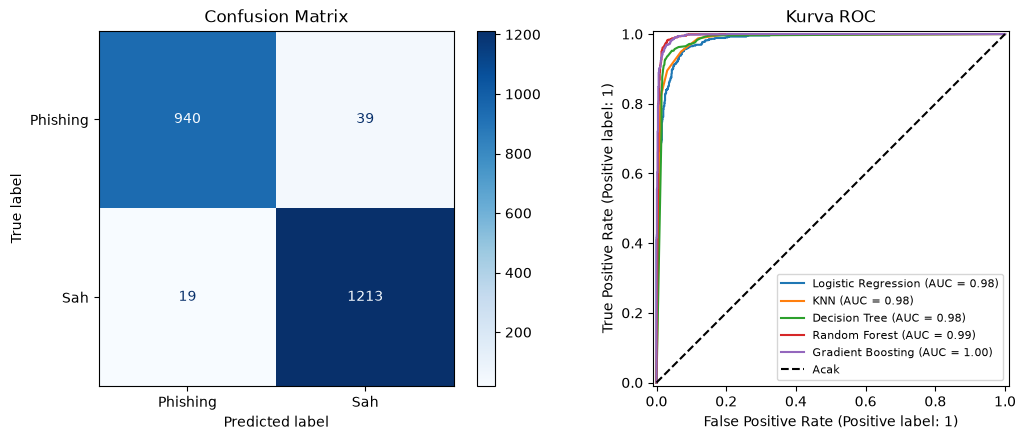

In [11]:
nama_terbaik = hasil_test.index[0]
terbaik = fitted[nama_terbaik]
pred = terbaik.predict(X_test)

print("Model terbaik:", nama_terbaik)
print(classification_report(y_test, pred, target_names=["Phishing (0)", "Sah (1)"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Phishing", "Sah"],
                                        cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion Matrix")
for nama, model in fitted.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=nama, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Acak")
axes[1].set_title("Kurva ROC")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

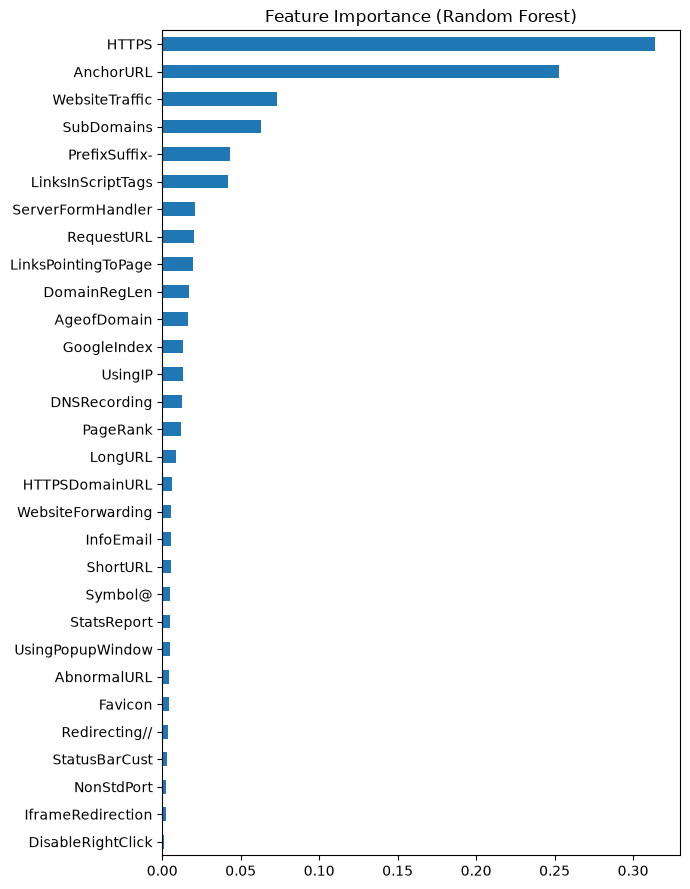

,importance
HTTPS,0.3142
AnchorURL,0.2525
WebsiteTraffic,0.0730
SubDomains,0.0631
PrefixSuffix-,0.0430
LinksInScriptTags,0.0416
ServerFormHandler,0.0206
RequestURL,0.0201
LinksPointingToPage,0.0196
DomainRegLen,0.0169


In [12]:
rf = fitted["Random Forest"].named_steps["clf"] if hasattr(fitted["Random Forest"], "named_steps") \
     else fitted["Random Forest"]

penting = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
plt.figure(figsize=(7, 9))
penting.plot(kind="barh")
plt.title("Feature Importance (Random Forest)")
plt.tight_layout()
plt.show()

display(penting.sort_values(ascending=False).head(10).round(4).to_frame("importance"))

In [13]:
# Prediksi 5 baris pertama data test
contoh = X_test.head(5)
hasil = pd.DataFrame({
    "aktual": y_test.head(5).map({0: "Phishing", 1: "Sah"}),
    "prediksi": pd.Series(terbaik.predict(contoh), index=contoh.index).map({0: "Phishing", 1: "Sah"}),
    "prob_sah": terbaik.predict_proba(contoh)[:, 1].round(3),
})
display(hasil)

# Simpan model
import joblib
joblib.dump(terbaik, "model_phishing.pkl")
print("Model tersimpan: model_phishing.pkl")

,aktual,prediksi,prob_sah
14,Phishing,Phishing,0.00
1415,Phishing,Phishing,0.01
904,Sah,Sah,1.00
9069,Phishing,Phishing,0.03
1644,Phishing,Phishing,0.00


Model tersimpan: model_phishing.pkl


# README: Dataset Phishing Websites

## Ringkasan dataset

| Item | Keterangan |
|---|---|
| File | `phishing.csv` (dengan header), `phishing.txt` (data yang sama tanpa header) |
| Jumlah data | 11.054 baris pada CSV (TXT berisi 11.055 baris dengan urutan berbeda) |
| Kolom | 32 kolom: `Index` (nomor urut), 30 fitur, 1 target (`class`) |
| Tipe fitur | Semua bernilai `-1`, `0`, atau `1` (hasil pengkodean aturan) |
| Target | `class` |
| Missing value | Tidak ada |
| Data test terpisah | Tidak ada, sehingga data dibagi sendiri menjadi train dan test |

Setiap baris mewakili satu website. Fiturnya adalah ciri-ciri yang diekstrak dari URL dan halaman, misalnya `UsingIP`, `HTTPS`, `AnchorURL`, `SubDomains`, `PrefixSuffix-`, `WebsiteTraffic`, dan `AgeofDomain`.

## Mengapa ini termasuk klasifikasi biner

1. **Pembelajaran terawasi (supervised).** Setiap website sudah diberi label pada kolom `class`.
2. **Targetnya kategorikal, bukan angka kontinu.** `class` menyatakan jenis website (sah atau phishing), bukan besaran yang diukur. Karena itu masalahnya bukan regresi.
3. **Targetnya hanya punya tepat dua nilai.**

| Nilai `class` | Arti | Jumlah | Persentase |
|---|---|---|---|
| 1 | Website sah (legitimate) | 6.157 | 55,7% |
| -1 | Website phishing | 4.897 | 44,3% |

Pada notebook, nilai `-1` dikodekan ulang menjadi `0` supaya mengikuti konvensi biner 0/1. Pengkodean ulang ini tidak mengubah sifat masalahnya.

4. **Kedua kelas saling lepas.** Satu website hanya masuk ke salah satu kelas, tanpa kelas ketiga.
5. **Keluaran model berupa keputusan dua pilihan:** website ini sah atau phishing.

## Karakteristik penting

- **Kelas relatif seimbang** (sekitar 56:44), sehingga akurasi cukup layak dipakai bersama precision, recall, dan F1.
- Nilai `0` pada fitur berarti "mencurigakan" atau "tidak pasti" pada aturan pengkodeannya. Itu adalah nilai fitur, bukan nilai target. Targetnya tetap hanya dua kelas.
- Ada 5.205 baris dengan nilai fitur identik, hal yang wajar karena tiap fitur hanya punya 3 nilai. Skor validasi bisa sedikit lebih optimis karena baris yang sama dapat muncul di data train dan validasi.
- Kolom `Index` dibuang dari fitur karena hanya nomor urut. Pada data ini, kelas `1` berarti website **sah**, jadi hati-hati saat membaca precision dan recall kelas 1 jika fokusnya mendeteksi phishing.

## Hasil baseline (5-fold cross-validation)

| Model | Accuracy | F1 | ROC-AUC |
|---|---|---|---|
| Logistic Regression | 0,927 | 0,935 | 0,979 |
| KNN | 0,939 | 0,945 | 0,983 |
| Decision Tree | 0,945 | 0,951 | 0,984 |
| Random Forest | 0,971 | 0,974 | 0,996 |
| Gradient Boosting | 0,967 | 0,971 | 0,996 |

Berbeda dari dua dataset lain, fitur di sini punya sinyal yang kuat. Fitur terpenting menurut Random Forest adalah `HTTPS`, `AnchorURL`, `WebsiteTraffic`, `SubDomains`, dan `LinksInScriptTags`.